# Analisis Galat Model

Notebook ini hanya **membaca dan menjelaskan** galat model pada test set (Mei-Jun 2026).
Test set sudah dibuka satu kali, jadi model, fitur, dan parameter **tidak diubah**
berdasarkan temuan di sini. Temuan dipakai untuk bagian keterbatasan laporan.

In [2]:
import sys
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# naik satu tingkat dari notebooks/ agar folder `src` terbaca
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import buat_fitur

df = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["waktu"]).set_index("waktu")
model = joblib.load(ROOT / "artifacts" / "model.joblib")
meta = json.loads((ROOT / "artifacts" / "metadata.json").read_text())

X_all = buat_fitur(df, pakai_lag=False)[meta["fitur_masukan"]]
print("ROOT:", ROOT)
print(X_all.shape, meta["fitur_masukan"], meta["versi"])

Matplotlib is building the font cache; this may take a moment.


ROOT: c:\Users\Pongo\Documents\SEMESTER 5\Building_Energy_Consumption\Building_Energy_Consumption
(21888, 6) ['jam', 'hari_minggu', 'bulan', 'suhu_luar_C', 'okupansi_orang', 'hari_libur'] 1.1.0


In [3]:
TEST_AWAL, TEST_AKHIR = "2026-05-01 00:00", "2026-06-30 23:00"

y = df["konsumsi_kWh"]
beda_libur = df["hari_libur"] != df["hari_libur"].shift(168)

ok = df["target_valid"] & X_all.notna().all(axis=1)
in_test = (df.index >= TEST_AWAL) & (df.index <= TEST_AKHIR)
mask = ok & in_test

test = df[mask].copy()
test["pred"] = model.predict(X_all[mask])             # tanpa pembulatan
test["galat"] = test["pred"] - test["konsumsi_kWh"]   # negatif = model terlalu rendah
test["abs_galat"] = test["galat"].abs()
test["beda_libur"] = beda_libur[mask]

mae = test["abs_galat"].mean()
bias = test["galat"].mean()
print(f"Baris dinilai   : {len(test)}")
print(f"MAE             : {mae:.2f}  (tim: 4,97)")
print(f"Bias            : {bias:.2f}  (tim: -0,34)")
print(f"MAE minggu biasa: {test.loc[~test['beda_libur'], 'abs_galat'].mean():.2f}  (tim: 4,99)")
print(f"MAE minggu libur: {test.loc[test['beda_libur'], 'abs_galat'].mean():.2f}  (tim: 4,85)")

Baris dinilai   : 1449
MAE             : 4.97  (tim: 4,97)
Bias            : -0.34  (tim: -0,34)
MAE minggu biasa: 4.99  (tim: 4,99)
MAE minggu libur: 4.85  (tim: 4,85)


## Pemeriksaan
MAE 4,97, bias -0,34, MAE minggu biasa 4,99, dan minggu libur 4,85 cocok dengan hasil tim,
jadi notebook memakai model dan data yang sama.

C:\Users\Pongo\AppData\Local\Temp\ipykernel_22788\918232209.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  test["hari"] = test.index.dayofweek


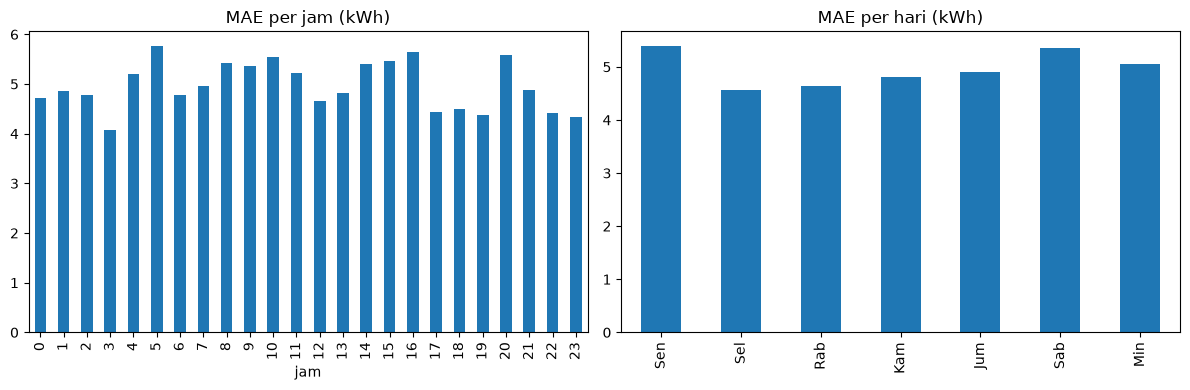

jam          0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23
abs_galat  4.72  4.86  4.79  4.07  5.21  5.77  4.77  4.97  5.42  5.37  5.54  5.23  4.65  4.82  5.41  5.46  5.65  4.43  4.50  4.38  5.58  4.88  4.42  4.34
galat      0.59  0.61 -0.14 -1.00 -2.34  2.10 -0.17 -1.31 -0.81 -0.55  1.23 -0.86 -0.31 -0.85 -2.65 -0.16  0.17 -0.50 -0.73 -0.87 -0.02  1.06 -0.01 -0.66
           Sen   Sel   Rab   Kam   Jum   Sab   Min
abs_galat  5.4  4.56  4.65  4.82  4.90  5.35  5.05
galat      0.1 -0.61 -0.13 -0.53 -0.35 -0.85 -0.00


In [4]:
nama_hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
test["jam"] = test.index.hour
test["hari"] = test.index.dayofweek

per_jam = test.groupby("jam")[["abs_galat", "galat"]].mean()
per_hari = test.groupby("hari")[["abs_galat", "galat"]].mean()
per_hari.index = nama_hari

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_jam["abs_galat"].plot.bar(ax=ax[0], title="MAE per jam (kWh)")
per_hari["abs_galat"].plot.bar(ax=ax[1], title="MAE per hari (kWh)")
plt.tight_layout()
plt.show()

print(per_jam.round(2).T.to_string())
print(per_hari.round(2).T.to_string())

count    1449.0
mean       23.7
std         4.1
min        14.5
25%        20.1
50%        23.7
75%        27.4
max        33.5
Name: suhu_luar_C, dtype: float64
count    1449.0
mean      132.0
std       202.0
min         0.0
25%         0.0
50%         0.0
75%       354.0
max       572.0
Name: okupansi_orang, dtype: float64
              abs_galat  galat    n
rentang_suhu                       
(14, 20]           4.75  -0.26  358
(20, 24]           4.96  -0.13  394
(24, 28]           5.14  -0.26  414
(28, 34]           5.00  -0.85  283 

                  abs_galat  galat    n
rentang_okupansi                       
0                      4.81  -0.10  737
1-200                  5.12  -1.04  321
201-400                5.41  -0.70   73
401-600                5.07  -0.09  318 



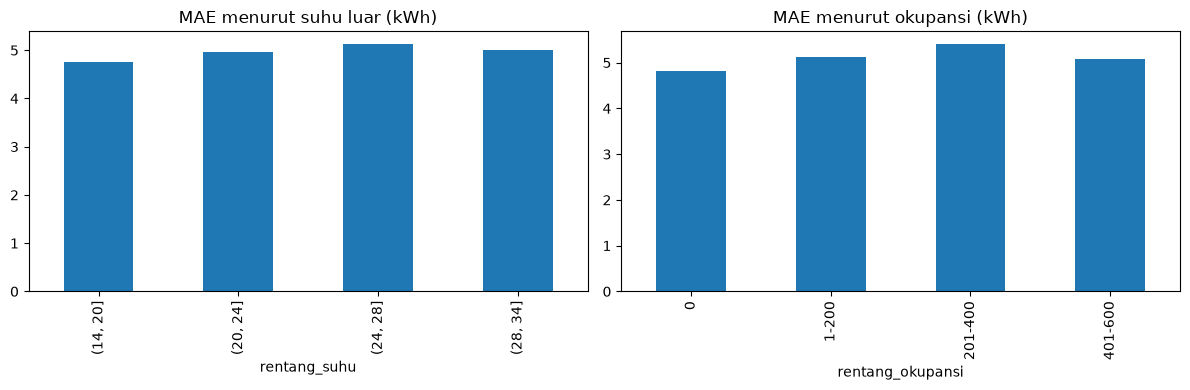

In [7]:
print(test["suhu_luar_C"].describe().round(1))
print(test["okupansi_orang"].describe().round(0))
test["rentang_suhu"] = pd.cut(test["suhu_luar_C"], bins=[14, 20, 24, 28, 34])
test["rentang_okupansi"] = pd.cut(
    test["okupansi_orang"], bins=[-1, 0, 200, 400, 600],
    labels=["0", "1-200", "201-400", "401-600"])

for kolom in ["rentang_suhu", "rentang_okupansi"]:
    ringkas = test.groupby(kolom, observed=True)[["abs_galat", "galat"]].mean()
    ringkas["n"] = test.groupby(kolom, observed=True).size()
    print(ringkas.round(2).to_string(), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
test.groupby("rentang_suhu", observed=True)["abs_galat"].mean().plot.bar(
    ax=ax[0], title="MAE menurut suhu luar (kWh)")
test.groupby("rentang_okupansi", observed=True)["abs_galat"].mean().plot.bar(
    ax=ax[1], title="MAE menurut okupansi (kWh)")
plt.tight_layout()
plt.show()

       abs_galat  galat    n
waktu                       
5           4.95  -0.33  737
6           4.98  -0.34  712


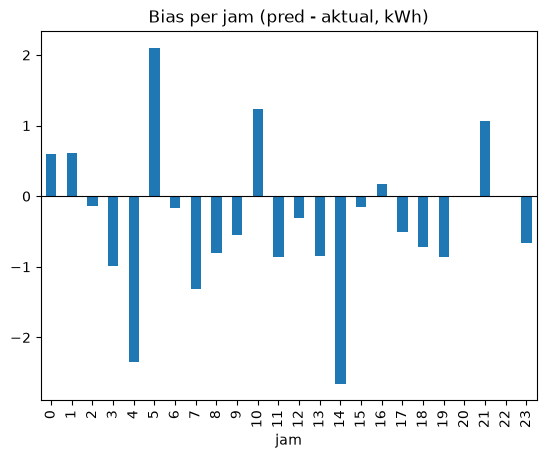

In [8]:
per_bulan = test.groupby(test.index.month)[["abs_galat", "galat"]].mean()
per_bulan["n"] = test.groupby(test.index.month).size()
print(per_bulan.round(2).to_string())

per_jam["galat"].plot.bar(title="Bias per jam (pred - aktual, kWh)")
plt.axhline(0, color="k", lw=0.8)
plt.show()

In [9]:
besar = test.nlargest(10, "abs_galat")[
    ["konsumsi_kWh", "pred", "galat", "suhu_luar_C", "okupansi_orang", "hari_libur"]]
print(besar.round(1).to_string())

                     konsumsi_kWh   pred  galat  suhu_luar_C  okupansi_orang  hari_libur
waktu                                                                                   
2026-06-13 14:00:00         138.1  103.5  -34.6         28.2            21.0           0
2026-05-02 14:00:00         130.9  103.5  -27.4         28.2            21.0           0
2026-05-30 16:00:00         126.7   99.7  -27.0         25.3            21.0           0
2026-06-13 13:00:00         127.7  101.3  -26.4         27.8            20.0           0
2026-05-08 15:00:00         340.5  363.0   22.5         33.5           474.0           0
2026-05-04 10:00:00         261.6  239.2  -22.4         21.5           469.0           0
2026-05-09 08:00:00         119.6   97.8  -21.8         25.1            21.0           0
2026-06-22 03:00:00         105.7   84.6  -21.1         18.3             0.0           0
2026-05-18 09:00:00         307.5  286.7  -20.8         23.6           569.0           0
2026-06-12 09:00:00  

In [10]:
lag168 = df["konsumsi_filled"].shift(168)
mask_b = mask & lag168.notna()
mae_base = (lag168 - y)[mask_b].abs().mean()
print(f"MAE baseline lag-168 = {mae_base:.2f}  (tim: 24,24)")
print(f"MAE model            = {mae:.2f}")

MAE baseline lag-168 = 24.24  (tim: 24,24)
MAE model            = 4.97


## Ringkasan temuan

Pemeriksaan: MAE 4,97, bias -0,34, minggu biasa 4,99, minggu libur 4,85, dan baseline 24,24 cocok dengan hasil tim (1.449 baris dinilai).

- **Jam dan hari:** MAE per jam berkisar 4,07-5,77 kWh dan per hari 4,56-5,40 kWh. Tidak ada jam atau hari yang jelas bermasalah. Bias per jam bolak-balik positif dan negatif tanpa pola tetap. Tiap jam hanya punya sekitar 60 baris, sehingga selisih kecil tidak ditafsirkan berlebihan.
- **Suhu:** MAE tidak membesar saat panas (4,75-5,14 kWh). Bias paling negatif pada 28-34 °C (-0,85), yaitu model cenderung menebak sedikit rendah saat panas.
- **Okupansi:** MAE 5,07-5,41 kWh di semua rentang okupansi.
- **Bulan:** Mei dan Juni hampir sama (bias -0,33 dan -0,34). Dua bulan test tidak cukup untuk menguji dugaan bahwa tren naik 4-5% per tahun membuat model menebak terlalu rendah.
- **Galat terbesar:** 8 dari 10 galat terbesar berupa tebakan terlalu rendah (20-35 kWh). Empat di antaranya terjadi pada Sabtu siang (13.00-16.00) dengan okupansi sekitar 20 orang. Dugaan, belum terbukti: beban pendingin pada akhir pekan yang hangat tidak sepenuhnya tertangkap oleh okupansi dan suhu.
- **Baseline:** model (4,97) jauh lebih baik daripada baseline lag-168 (24,24).

**Catatan:** temuan ini hanya untuk bagian keterbatasan laporan. Test set sudah dibuka satu kali, sehingga model, fitur, dan parameter tidak diubah berdasarkan hasil ini.